# 07 — Multi-period cross-sensor association review

This notebook repeats the candidate-link exploration for seven archive-only months spanning 2025 and January–July 2026. It uses a fixed 1 km / 3 hour envelope to compare behavior across periods, not to estimate accuracy. Archive-only selection avoids mixing NRT and archive in a period. Each row remains a raw observation; candidate edges are not fires/events.

No ground-truth event labels are available. Candidate counts, link ratios, and graph participation must not be interpreted as precision, recall, true-fire counts, or proof of harmonization quality.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.firewatch.association import find_candidate_links
DATA = ROOT / 'data' / 'processed' / 'observations.parquet'
columns = ['observation_id','satellite','product_code','latitude_num','longitude_num','observation_datetime_utc','validation_status','stream_type']
obs = pd.read_parquet(DATA, columns=columns)
obs['observation_datetime_utc'] = pd.to_datetime(obs.observation_datetime_utc, utc=True)
print(f'{len(obs):,} normalized rows loaded')


1,130,027 normalized rows loaded


In [2]:
months = ['2025-01','2025-04','2025-07','2025-10','2026-01','2026-04','2026-07']
summary_rows, pair_rows = [], []
for month in months:
    start = pd.Timestamp(month + '-01', tz='UTC')
    end = start + pd.offsets.MonthEnd(0) + pd.Timedelta(days=1)
    sample = obs.loc[obs.observation_datetime_utc.ge(start) & obs.observation_datetime_utc.lt(end) & obs.stream_type.eq('archive')]
    links = find_candidate_links(sample, max_distance_km=1, max_time_delta_hours=3)
    linked_ids = set(links.left_observation_id) | set(links.right_observation_id) if len(links) else set()
    cross = links.loc[links.link_family.eq('MODIS-VIIRS')] if len(links) else links
    summary_rows.append({'month':month,'archive_observations':len(sample),'platforms':', '.join(sorted(sample.satellite.unique())),
        'candidate_pairs':len(links),'pairs_per_1000_rows':len(links)/len(sample)*1000 if len(sample) else 0,
        'distinct_observations_in_any_link':len(linked_ids),'observation_share_in_any_link':len(linked_ids)/len(sample) if len(sample) else 0,
        'MODIS_VIIRS_pairs':len(cross),'VIIRS_platform_pairs':int(links.link_family.eq('VIIRS-platform').sum()),
        'MODIS_platform_pairs':int(links.link_family.eq('MODIS-platform').sum()),
        'median_distance_km':links.distance_km.median() if len(links) else float('nan'),
        'median_time_difference_min':links.time_difference_minutes.median() if len(links) else float('nan')})
    if len(cross):
        pairs = cross.groupby(['left_satellite','right_satellite']).size().rename('candidate_pairs').reset_index()
        pairs.insert(0,'month',month); pair_rows.append(pairs)
summary = pd.DataFrame(summary_rows)
pair_summary = pd.concat(pair_rows, ignore_index=True) if pair_rows else pd.DataFrame()
display(summary.round({'pairs_per_1000_rows':1,'observation_share_in_any_link':3,'median_distance_km':3,'median_time_difference_min':1}))


,month,archive_observations,platforms,candidate_pairs,pairs_per_1000_rows,distinct_observations_in_any_link,observation_share_in_any_link,MODIS_VIIRS_pairs,VIIRS_platform_pairs,MODIS_platform_pairs,median_distance_km,median_time_difference_min
0,2025-01,221667,"Aqua, N20, N21, SNPP, Terra",317546,1432.5,161818,0.730,33268,284278,0,0.463,26.0
1,2025-04,12790,"Aqua, N20, N21, SNPP, Terra",17294,1352.2,7629,0.596,1076,16218,0,0.480,26.0
2,2025-07,430,"Aqua, N20, N21, SNPP, Terra",157,365.1,154,0.358,18,139,0,0.389,51.0
3,2025-10,4727,"Aqua, N20, N21, SNPP, Terra",3985,843.0,2340,0.495,332,3653,0,0.526,29.0
4,2026-01,146995,"Aqua, N20, N21, SNPP, Terra",188017,1279.1,100040,0.681,14312,173705,0,0.468,30.0
5,2026-04,6522,"Aqua, N20, N21, SNPP, Terra",6422,984.7,3083,0.473,335,6087,0,0.488,49.0
6,2026-07,937,"Aqua, N20, N21, SNPP, Terra",981,1047.0,476,0.508,42,939,0,0.452,35.0


In [3]:
display(pair_summary.pivot_table(index='month', columns=['left_satellite','right_satellite'], values='candidate_pairs', fill_value=0) if not pair_summary.empty else pair_summary)


left_satellite      Aqua                      N20   N21   SNPP
right_satellite      N20      N21     SNPP  Terra Terra  Terra
month                                                         
2025-01          10792.0  10223.0  11593.0  435.0  37.0  188.0
2025-04            387.0    301.0    331.0    6.0  24.0   27.0
2025-07              2.0     12.0      4.0    0.0   0.0    0.0
2025-10             86.0    104.0    137.0    5.0   0.0    0.0
2026-01           5057.0   4439.0   4810.0    6.0   0.0    0.0
2026-04            122.0    114.0     99.0    0.0   0.0    0.0
2026-07             15.0     13.0     14.0    0.0   0.0    0.0

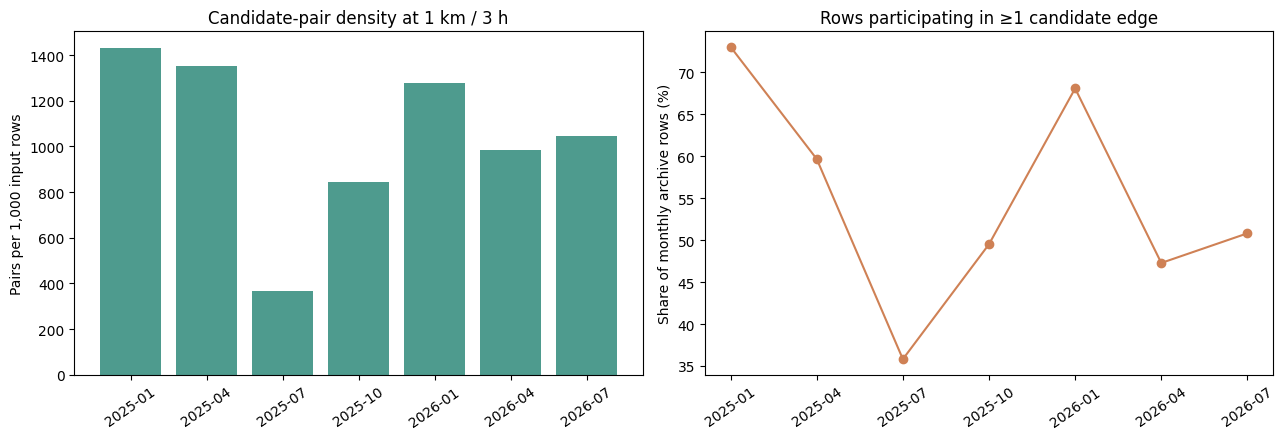

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(summary.month, summary.pairs_per_1000_rows, color='#4e9b8e')
axes[0].set_title('Candidate-pair density at 1 km / 3 h'); axes[0].set_ylabel('Pairs per 1,000 input rows'); axes[0].tick_params(axis='x', rotation=35)
axes[1].plot(summary.month, summary.observation_share_in_any_link*100, marker='o', color='#cf8155')
axes[1].set_title('Rows participating in ≥1 candidate edge'); axes[1].set_ylabel('Share of monthly archive rows (%)'); axes[1].tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.show()


## Interpretation

The candidate graph is dense in some selected months and varies strongly with monthly observation volume. A high linked-row share does not mean that those pairs are true co-observations: many rows can have multiple near-neighbors, particularly across VIIRS platforms. The graph preserves evidence but needs independent validation before a one-to-one matcher, clustering, anomaly model, or harmonized event count is justified.

Months were sampled across the available period; the selected months are not a balanced seasonal study. July/April counts are especially sparse relative to January in this extract, so do not infer sensor performance changes from these comparisons. MODIS/VIIRS FRP and confidence scales must remain source-native.
